# **Project Name**    - Tata Steel Machine Failure Prediction



##### **Project Type**    - Classification



##### **Contribution**    - Individual
##### **Team Member 1 -** Yash vyas
##### **Team Member 2 -**
##### **Team Member 3 -**
##### **Team Member 4 -**

# **Project Summary -**
This project focuses on predicting whether an industrial machine is likely to experience a failure based on operating conditions such as air temperature, process temperature, rotational speed, torque, tool wear, and machine type. Predictive maintenance is an important business use case because unexpected machine failures can interrupt production, increase maintenance costs, reduce equipment availability, and affect product delivery schedules.
The dataset contains a labeled training dataset and an unlabeled test dataset. The training data is used to understand relationships between machine operating conditions and the target variable, Machine failure. Exploratory Data Analysis is performed using statistical summaries and visualizations to identify distributions, relationships, imbalance, and potentially important operational patterns.
The project then prepares the data for machine learning by removing identifiers that do not provide useful predictive information, encoding the categorical machine Type variable, scaling numerical variables where required, and separating the target from the explanatory features. Because machine failure is relatively rare compared with normal operation, model evaluation focuses not only on accuracy but also on precision, recall, F1-score, ROC-AUC, and the confusion matrix.
Classification models are trained and compared. Cross-validation and hyperparameter tuning are used to improve the selected model. Finally, the model results are interpreted from a business perspective, with particular attention to identifying failures early. A model that can identify more true failures can help maintenance teams prioritize inspections and reduce unexpected downtime, while false alarms should also be controlled so that maintenance resources are not wasted.
The final notebook presents the complete analytical workflow from business understanding and EDA to preprocessing, model building, evaluation, tuning, and business interpretation.

Write the summary here within 500-600 words.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


**Write Problem Statement Here.**

Industrial machines can fail because of abnormal operating conditions, excessive tool wear, high torque, temperature-related stress, or other operational factors. Unexpected failures may cause production downtime, emergency maintenance, additional costs, and disruption to business operations.
The objective of this project is to build a binary classification model that predicts whether a machine will experience a failure using the available operational measurements and machine type. The analysis will identify patterns associated with failure, evaluate multiple classification algorithms, and select a model based on appropriate performance metrics.
The business objective is to support predictive maintenance. If machines with a higher probability of failure can be identified in advance, maintenance teams can prioritize inspections and interventions before a breakdown occurs. Since failure cases are much less frequent than normal cases, recall and F1-score are important alongside accuracy.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [375]:
# Import required libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')


### Dataset Loading

In [376]:
# Upload train.csv and test.csv to Colab before running this cell.
# If the files are already present in the Colab working directory, this will load them directly.

train_path = '/content/train.csv'
test_path = '/content/test.csv'

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)


Train shape: (136429, 14)
Test shape : (90954, 13)


### Dataset First View

In [377]:
# Display the first five records
display(train_df.head())

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.600,309.600,1596,36.100,140,0,0,0,0,0,0
1,1,M20343,M,302.600,312.100,1759,29.100,200,0,0,0,0,0,0
2,2,L49454,L,299.300,308.500,1805,26.500,25,0,0,0,0,0,0
3,3,L53355,L,301.000,310.900,1524,44.300,197,0,0,0,0,0,0
4,4,M24050,M,298.000,309.000,1641,35.400,34,0,0,0,0,0,0


### Dataset Rows & Columns count

In [378]:
print(f"Training dataset contains {train_df.shape[0]:,} rows and {train_df.shape[1]} columns.")
print(f"Testing dataset contains {test_df.shape[0]:,} rows and {test_df.shape[1]} columns.")


Training dataset contains 136,429 rows and 14 columns.
Testing dataset contains 90,954 rows and 13 columns.


### Dataset Information

In [379]:
# Dataset structure and data types
train_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  object 
 2   Type                     136429 non-null  object 
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: f

#### Duplicate Values

In [380]:
print("Duplicate rows in training data:", train_df.duplicated().sum())
print("Duplicate rows in test data:", test_df.duplicated().sum())


Duplicate rows in training data: 0
Duplicate rows in test data: 0


#### Missing Values/Null Values

In [381]:
missing_train = train_df.isnull().sum().sort_values(ascending=False)
missing_test = test_df.isnull().sum().sort_values(ascending=False)

display(missing_train.to_frame('Missing Values - Train'))
display(missing_test.to_frame('Missing Values - Test'))


,Missing Values - Train
id,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


,Missing Values - Test
id,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
TWF,0
HDF,0


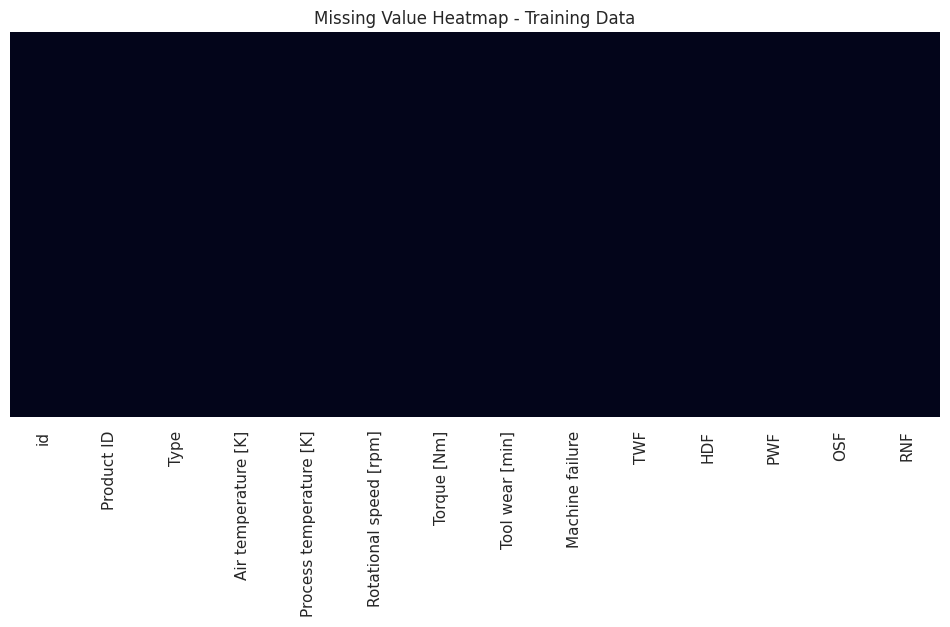

In [382]:
# Visualizing missing values
plt.figure(figsize=(12, 5))
sns.heatmap(train_df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing Value Heatmap - Training Data')
plt.show()


### What did you know about your dataset?

The training dataset contains 136,429 observations and 14 columns, while the test dataset contains 90,954 observations and 13 columns. The training dataset contains the target variable, Machine failure, while the test dataset does not contain this target because it is intended for prediction.
The variables include machine identifiers, machine type, temperature measurements, rotational speed, torque, tool wear, and several failure-mode indicator columns. The target is binary, where 0 represents no machine failure and 1 represents machine failure.
The dataset does not contain missing values and does not contain duplicate rows in the training data. However, the target is highly imbalanced: normal operation is much more common than failure. Therefore, model evaluation should not rely only on accuracy.
For predictive modeling, identifier columns such as id and Product ID are not treated as meaningful operational predictors. The failure-mode flags are also excluded from the primary predictive feature set because they are closely related to the failure outcome and may create target leakage if they represent failure conditions identified at or after failure. The model therefore focuses on operating conditions that can support an early-warning predictive maintenance use case.

## ***2. Understanding Your Variables***

In [383]:
# List all columns
print("Training columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

display(train_df.describe(include='all').T)


Training columns:
['id', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Test columns:
['id', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"136,429.000",NaN,NaN,NaN,"68,214.000","39,383.804",0.000,"34,107.000","68,214.000","102,321.000","136,428.000"
Product ID,136429,9976,L53257,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,136429,3,L,95354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],"136,429.000",NaN,NaN,NaN,299.863,1.862,295.300,298.300,300.000,301.200,304.400
Process temperature [K],"136,429.000",NaN,NaN,NaN,309.941,1.385,305.800,308.700,310.000,310.900,313.800
Rotational speed [rpm],"136,429.000",NaN,NaN,NaN,"1,520.331",138.737,"1,181.000","1,432.000","1,493.000","1,580.000","2,886.000"
Torque [Nm],"136,429.000",NaN,NaN,NaN,40.349,8.502,3.800,34.600,40.400,46.100,76.600
Tool wear [min],"136,429.000",NaN,NaN,NaN,104.409,63.965,0.000,48.000,106.000,159.000,253.000
Machine failure,"136,429.000",NaN,NaN,NaN,0.016,0.124,0.000,0.000,0.000,0.000,1.000
TWF,"136,429.000",NaN,NaN,NaN,0.002,0.039,0.000,0.000,0.000,0.000,1.000


### Variables Description

| Variable | Description |
|---|---|
| id | Unique row identifier |
| Product ID | Product/machine identifier |
| Type | Machine/product type category |
| Air temperature [K] | Ambient air temperature in Kelvin |
| Process temperature [K] | Operating process temperature in Kelvin |
| Rotational speed [rpm] | Rotational speed in revolutions per minute |
| Torque [Nm] | Torque applied to the machine in Newton-meters |
| Tool wear [min] | Accumulated tool wear in minutes |
| Machine failure | Binary target indicating whether a machine failure occurred |
| TWF | Tool wear failure indicator |
| HDF | Heat dissipation failure indicator |
| PWF | Power failure indicator |
| OSF | Overstrain failure indicator |
| RNF | Random failure indicator |

The main operational predictors are temperature, rotational speed, torque, tool wear, and machine type. The Machine failure column is the target variable. The failure-mode indicator columns are not used as primary predictors because they can expose information that is too closely connected to the failure outcome

### Check Unique Values for each variable.

In [384]:
# Check number of unique values for each variable
unique_counts = train_df.nunique().sort_values()
display(unique_counts.to_frame('Unique Values'))


,Unique Values
PWF,2
HDF,2
RNF,2
OSF,2
TWF,2
Machine failure,2
Type,3
Process temperature [K],81
Air temperature [K],95
Tool wear [min],246


## 3. ***Data Wrangling***

### Data Wrangling Code

In [385]:
# Create a working copy
df = train_df.copy()

# Remove duplicate rows as a safety check
df = df.drop_duplicates().reset_index(drop=True)

# Convert Type to a clean categorical string
df['Type'] = df['Type'].astype(str).str.strip()

# Check target values
print("Target values:", sorted(df['Machine failure'].unique()))

# Define columns that are identifiers or potentially leakage-prone failure indicators
id_columns = ['id', 'Product ID']
leakage_columns = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

print("Rows after duplicate removal:", len(df))


Target values: [np.int64(0), np.int64(1)]
Rows after duplicate removal: 136429


### What all manipulations have you done and insights you found?

The dataset was copied into a working DataFrame and duplicate rows were removed as a precaution. The Type variable was converted to a clean categorical string. Identifier columns such as id and Product ID were identified as non-operational identifiers rather than useful explanatory variables.
The five failure-mode indicators were identified separately because they describe specific failure conditions and are closely associated with the target. Using such variables directly in an early-warning prediction model can introduce target leakage. Therefore, the primary model uses machine operating conditions and machine type instead.
The target variable was checked to confirm that it contains two classes, 0 and 1. The target distribution is highly imbalanced, which means the modeling strategy must pay attention to minority-class recall and F1-score.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

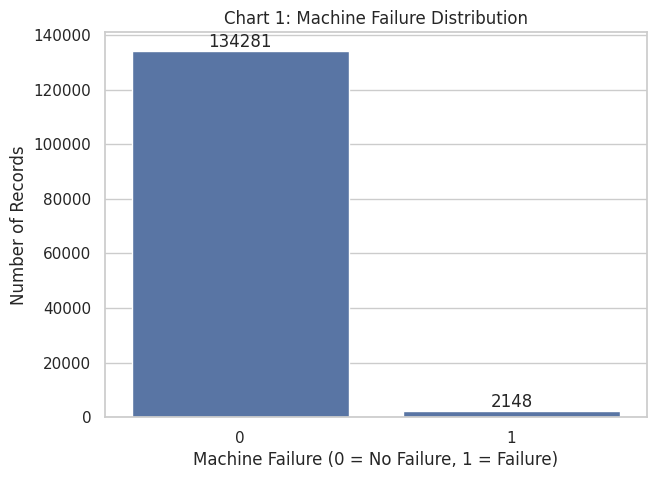

In [386]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Machine failure')
plt.title('Chart 1: Machine Failure Distribution')
plt.xlabel('Machine Failure (0 = No Failure, 1 = Failure)')
plt.ylabel('Number of Records')

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.show()


##### 1. Why did you pick the specific chart?

A count plot is appropriate because Machine failure is a binary categorical target. It clearly shows the number of normal and failed observations.

##### 2. What is/are the insight(s) found from the chart?

The dataset is strongly imbalanced. Normal observations are much more frequent than failure observations.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Machine failure is a relatively rare event, so a predictive model must detect the minority failure class effectively. Accuracy alone can be misleading; recall, precision and F1-score are important for maintenance planning.

#### Chart - 2

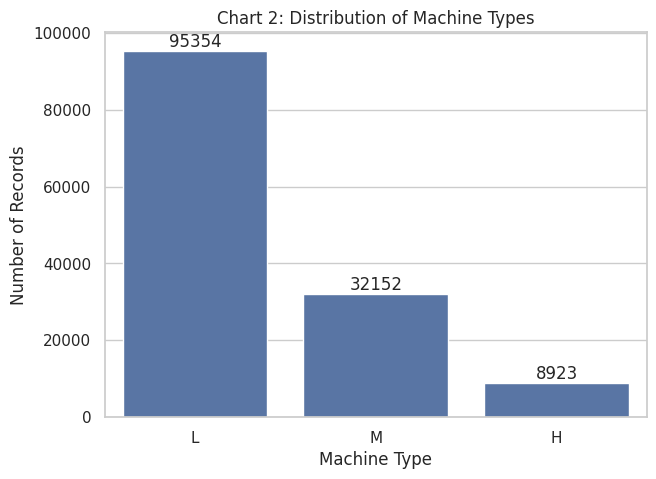

In [387]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Type')
plt.title('Chart 2: Distribution of Machine Types')
plt.xlabel('Machine Type')
plt.ylabel('Number of Records')
for container in ax.containers:
    ax.bar_label(container, fmt='%d')
plt.show()


##### 1. Why did you pick the specific chart?

A count plot is suitable for understanding the frequency of each categorical machine type.

##### 2. What is/are the insight(s) found from the chart?

The chart shows how observations are distributed among the available machine types.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding representation by machine type helps ensure that model performance is interpreted in the context of the available equipment categories and prevents conclusions from being based on an underrepresented category.

#### Chart - 3

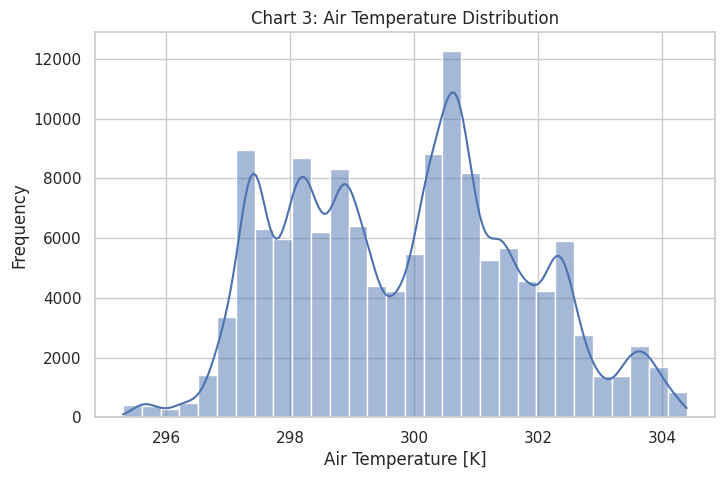

In [388]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Air temperature [K]', bins=30, kde=True)
plt.title('Chart 3: Air Temperature Distribution')
plt.xlabel('Air Temperature [K]')
plt.ylabel('Frequency')
plt.show()


##### 1. Why did you pick the specific chart?

A histogram with a density curve is useful for understanding the distribution and spread of a continuous numerical variable.

##### 2. What is/are the insight(s) found from the chart?

Air temperature is concentrated within a relatively narrow operating range, with some variation around its central values.




##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding the normal operating range provides a baseline for identifying unusual environmental conditions that could potentially contribute to equipment stress

#### Chart - 4

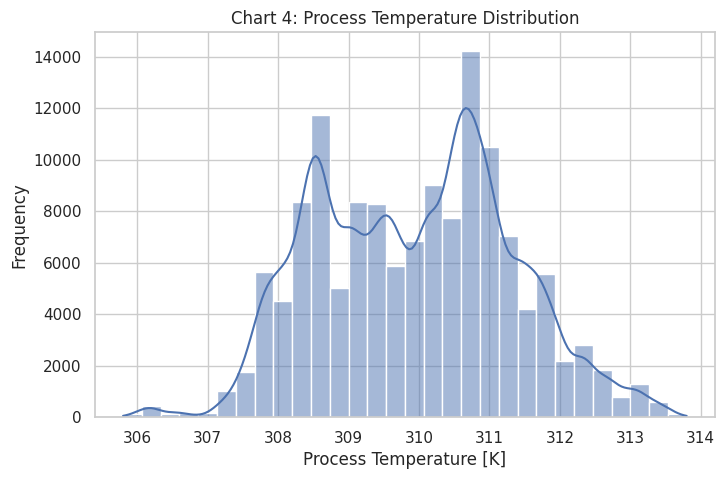

In [389]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Process temperature [K]', bins=30, kde=True)
plt.title('Chart 4: Process Temperature Distribution')
plt.xlabel('Process Temperature [K]')
plt.ylabel('Frequency')
plt.show()


##### 1. Why did you pick the specific chart?

A histogram is appropriate for examining the distribution of process temperature and identifying its typical operating range.

##### 2. What is/are the insight(s) found from the chart?

Process temperature is centered around its normal operating range, with relatively limited variation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Monitoring deviations from normal process temperature can support predictive maintenance and operational quality control.

#### Chart - 5

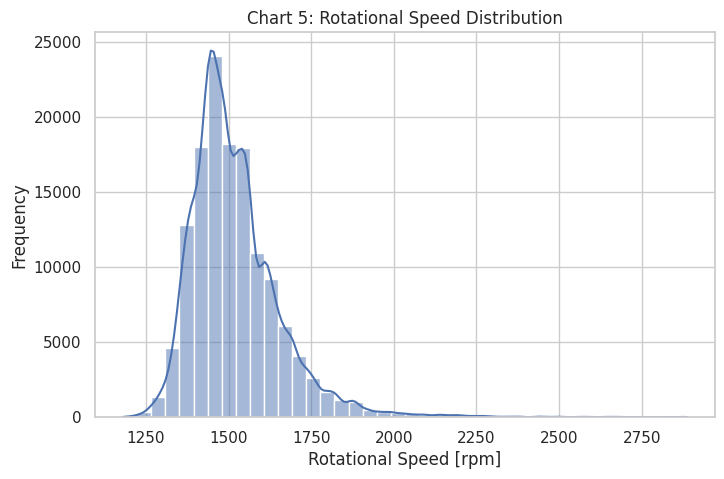

In [390]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Rotational speed [rpm]', bins=40, kde=True)
plt.title('Chart 5: Rotational Speed Distribution')
plt.xlabel('Rotational Speed [rpm]')
plt.ylabel('Frequency')
plt.show()


##### 1. Why did you pick the specific chart?

A histogram helps identify the typical rotational speed range and potential extreme operating values.

##### 2. What is/are the insight(s) found from the chart?

Most observations occur around the common operating speed range, while a smaller number of observations occur at higher or lower speeds.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Unusual rotational speeds can be investigated as potential warning signals, especially when they occur together with high torque or tool wear.

#### Chart - 6

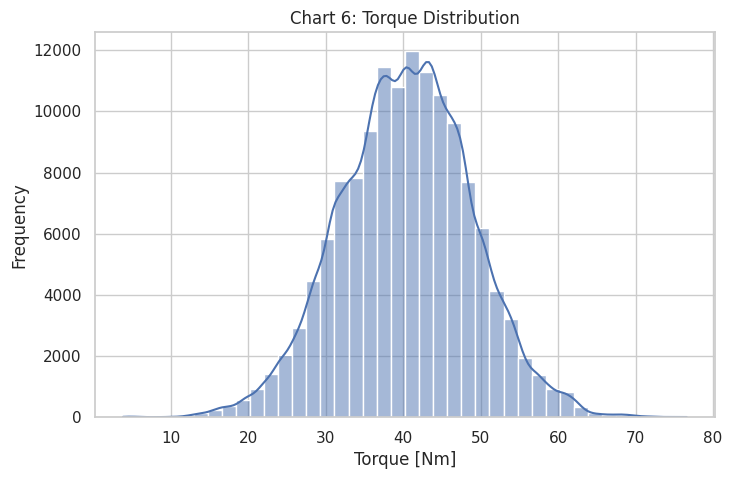

In [391]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Torque [Nm]', bins=40, kde=True)
plt.title('Chart 6: Torque Distribution')
plt.xlabel('Torque [Nm]')
plt.ylabel('Frequency')
plt.show()


##### 1. Why did you pick the specific chart?

Torque is a key machine-load variable, so a histogram helps understand its normal and extreme operating ranges.

##### 2. What is/are the insight(s) found from the chart?

Torque varies across the operating records and includes observations at relatively high levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

High mechanical load can increase stress on equipment. Understanding torque distribution can help maintenance teams investigate high-load operating conditions.

#### Chart - 7

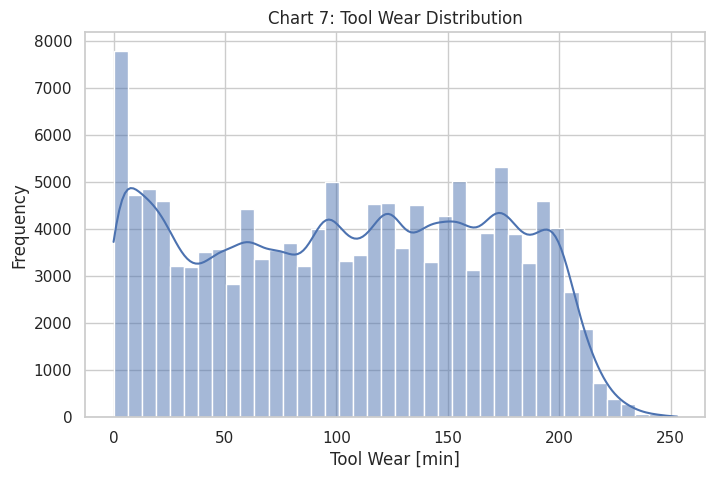

In [392]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Tool wear [min]', bins=40, kde=True)
plt.title('Chart 7: Tool Wear Distribution')
plt.xlabel('Tool Wear [min]')
plt.ylabel('Frequency')
plt.show()


##### 1. Why did you pick the specific chart?

A histogram is useful for understanding how tool wear accumulates across observations.

##### 2. What is/are the insight(s) found from the chart?

Tool wear spans a broad range from low to high values, allowing us to examine whether higher wear is associated with failure.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Tool wear can support maintenance scheduling. If higher wear is associated with increased failure risk, preventive replacement can reduce unexpected downtime.

#### Chart - 8

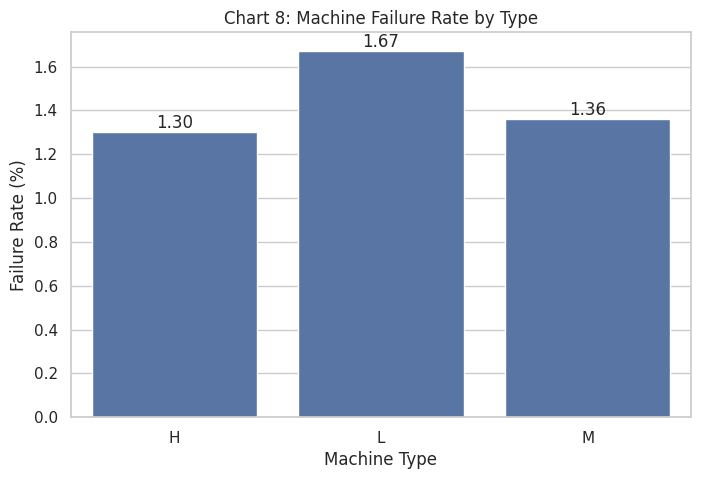

In [393]:
failure_by_type = df.groupby('Type')['Machine failure'].agg(['count', 'sum'])
failure_by_type['failure_rate_%'] = failure_by_type['sum'] / failure_by_type['count'] * 100
failure_by_type = failure_by_type.reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=failure_by_type, x='Type', y='failure_rate_%')
plt.title('Chart 8: Machine Failure Rate by Type')
plt.xlabel('Machine Type')
plt.ylabel('Failure Rate (%)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare failure rates across categorical machine types.

##### 2. What is/are the insight(s) found from the chart?

The chart compares the percentage of failed observations within each machine type rather than just comparing failure counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

If one machine type has a higher failure rate, maintenance teams can investigate whether that category requires different inspection intervals, operating limits, or maintenance procedures.

#### Chart - 9

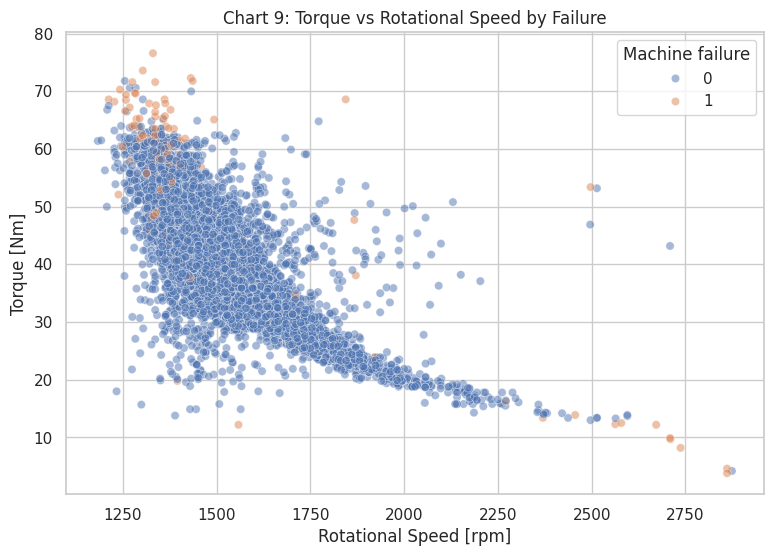

In [394]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df.sample(min(15000, len(df)), random_state=42),
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Machine failure',
    alpha=0.5
)
plt.title('Chart 9: Torque vs Rotational Speed by Failure')
plt.xlabel('Rotational Speed [rpm]')
plt.ylabel('Torque [Nm]')
plt.show()


##### 1. Why did you pick the specific chart?

A scatter plot is appropriate for studying the relationship between two numerical operating variables and adding failure status as a third dimension through color.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify whether failures are concentrated in particular combinations of rotational speed and torque.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

If risky combinations are visible, operational teams can investigate those operating regions and use them as part of a predictive maintenance warning system

#### Chart - 10

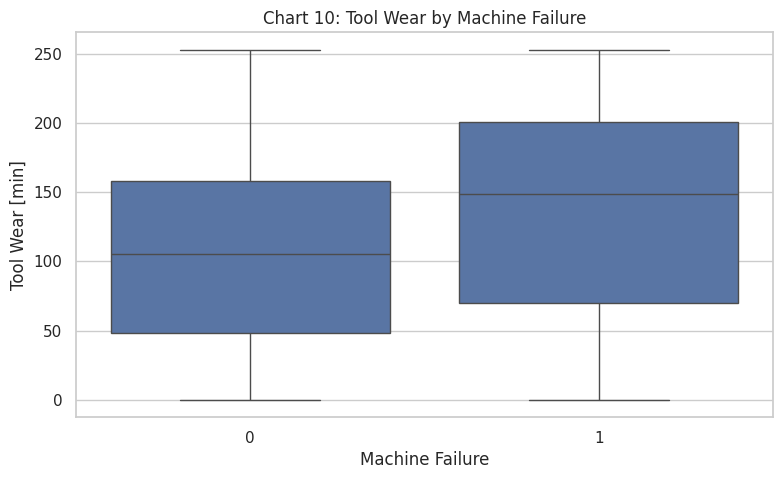

In [395]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Machine failure', y='Tool wear [min]')
plt.title('Chart 10: Tool Wear by Machine Failure')
plt.xlabel('Machine Failure')
plt.ylabel('Tool Wear [min]')
plt.show()


##### 1. Why did you pick the specific chart?

A box plot compares the distribution of tool wear between failed and non-failed observations and highlights differences in median and spread.

##### 2. What is/are the insight(s) found from the chart?

The chart allows us to determine whether failed observations tend to have different tool-wear levels from normal observations.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

If failure cases show higher tool wear, tool replacement or inspection thresholds can become part of preventive maintenance planning.

#### Chart - 11

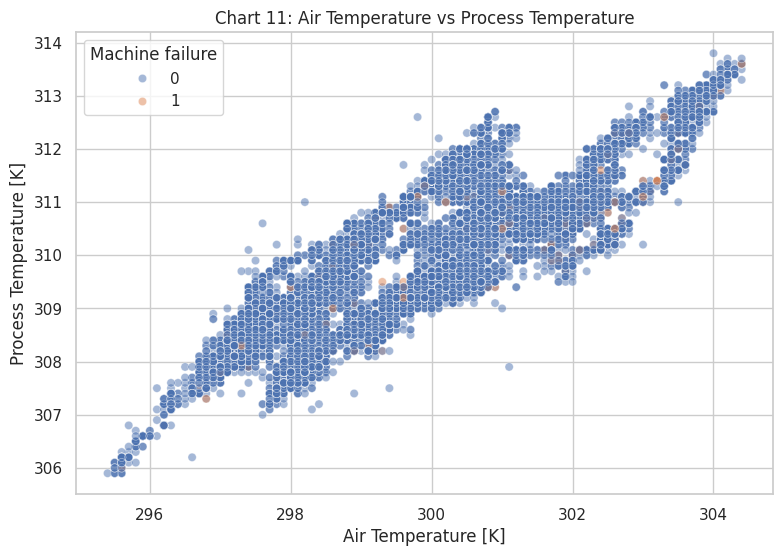

In [396]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df.sample(min(15000, len(df)), random_state=42),
    x='Air temperature [K]',
    y='Process temperature [K]',
    hue='Machine failure',
    alpha=0.5
)
plt.title('Chart 11: Air Temperature vs Process Temperature')
plt.xlabel('Air Temperature [K]')
plt.ylabel('Process Temperature [K]')
plt.show()


##### 1. Why did you pick the specific chart?

A scatter plot is suitable for examining the relationship between environmental and process temperature while highlighting failure cases.

##### 2. What is/are the insight(s) found from the chart?

The chart shows how process temperature varies with air temperature and whether failures appear concentrated in particular temperature combinations.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Temperature relationships can help identify operating conditions that deserve additional monitoring and may support condition-based maintenance.

#### Chart - 12

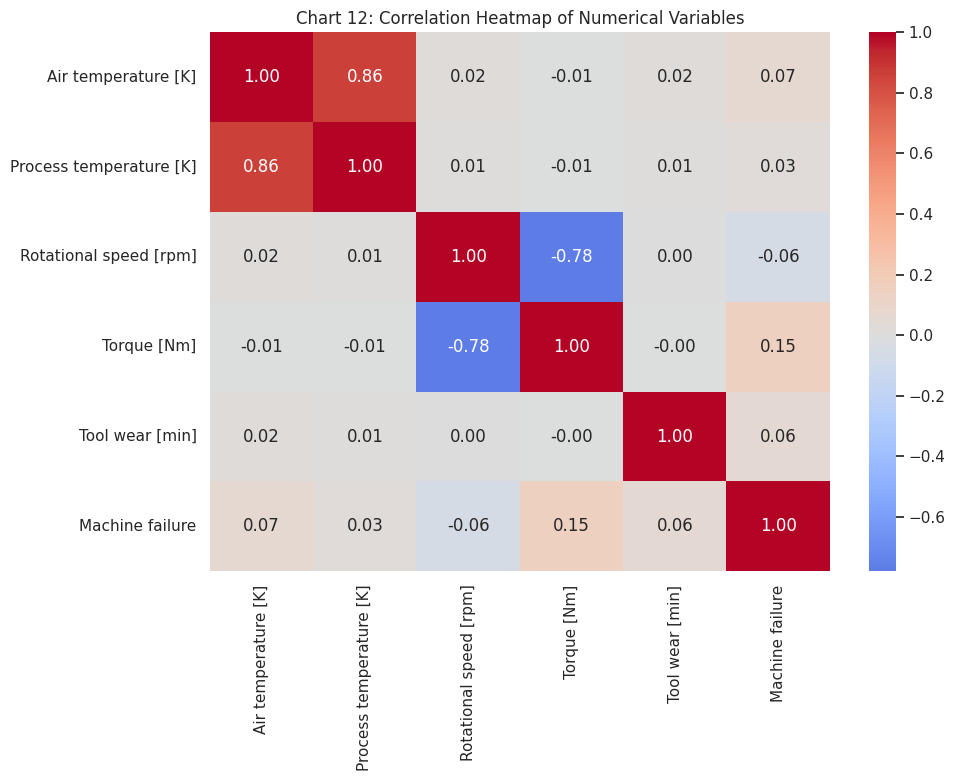

In [397]:
numeric_cols = [
    'Air temperature [K]', 'Process temperature [K]',
    'Rotational speed [rpm]', 'Torque [Nm]',
    'Tool wear [min]', 'Machine failure'
]

plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Chart 12: Correlation Heatmap of Numerical Variables')
plt.show()


##### 1. Why did you pick the specific chart?

A correlation heatmap summarizes pairwise linear relationships between multiple numerical variables in one visual.

##### 2. What is/are the insight(s) found from the chart?

It helps identify variables that move together and highlights the strength and direction of their linear associations.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding relationships between operating variables helps avoid redundant information and supports feature selection and model interpretation. Correlation does not prove causation.

#### Chart - 13

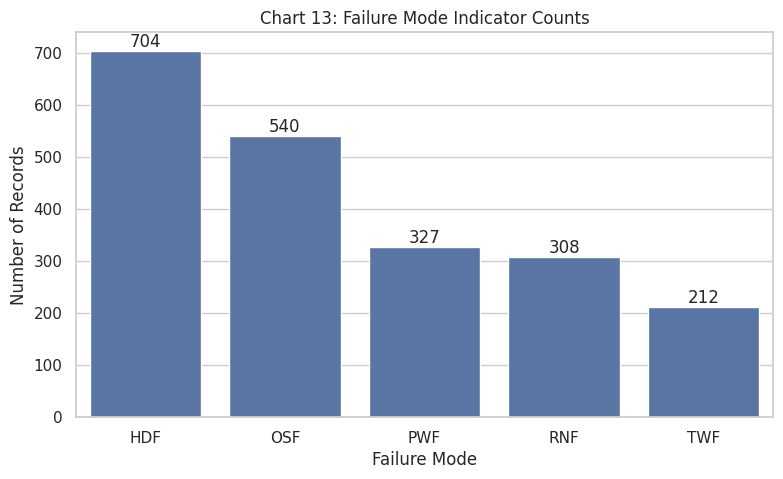

In [398]:
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
failure_counts = df[failure_modes].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=failure_counts.index, y=failure_counts.values)
plt.title('Chart 13: Failure Mode Indicator Counts')
plt.xlabel('Failure Mode')
plt.ylabel('Number of Records')
for container in ax.containers:
    ax.bar_label(container, fmt='%d')
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart is appropriate for comparing the frequency of the categorical failure-mode indicators.

##### 2. What is/are the insight(s) found from the chart?

The chart shows which recorded failure modes occur more frequently than others in the training data

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding failure-mode frequency can help maintenance teams prioritize investigation and preventive strategies. These indicators are treated as descriptive variables rather than predictors in the primary early-warning model.

#### Chart - 14 - Correlation Heatmap

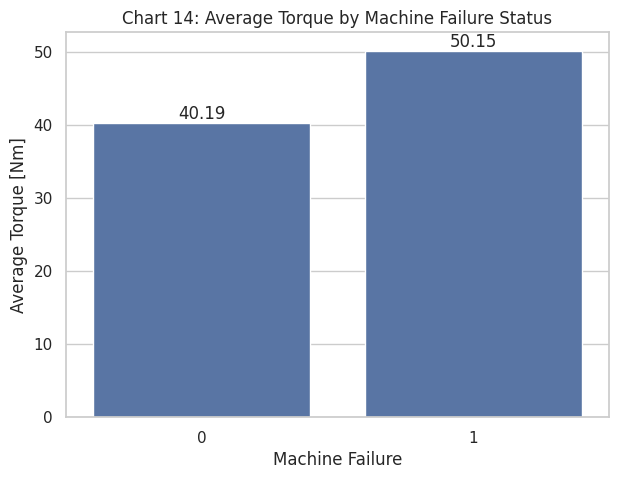

In [399]:
avg_torque = df.groupby('Machine failure')['Torque [Nm]'].mean().reset_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=avg_torque, x='Machine failure', y='Torque [Nm]')
plt.title('Chart 14: Average Torque by Machine Failure Status')
plt.xlabel('Machine Failure')
plt.ylabel('Average Torque [Nm]')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.show()


##### 1. Why did you pick the specific chart?

A grouped mean bar chart provides a simple comparison of average torque between normal and failure observations.

##### 2. What is/are the insight(s) found from the chart?

It shows whether failed observations have a different average torque level from normal observations.

#### Chart - 15 - Pair Plot

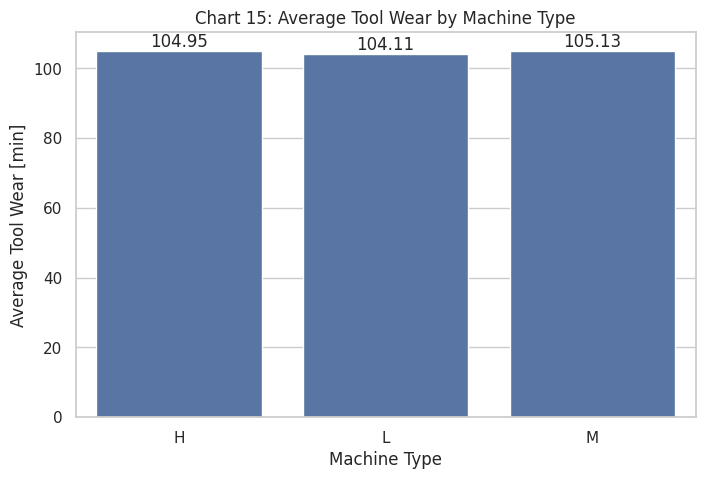

In [400]:
avg_wear = df.groupby('Type')['Tool wear [min]'].mean().reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=avg_wear, x='Type', y='Tool wear [min]')
plt.title('Chart 15: Average Tool Wear by Machine Type')
plt.xlabel('Machine Type')
plt.ylabel('Average Tool Wear [min]')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart allows comparison of average tool wear across machine types.

##### 2. What is/are the insight(s) found from the chart?

The chart shows whether some machine types operate with systematically different average tool-wear levels.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Hypothesis testing is used in this project to statistically validate relationships observed during exploratory data analysis. Three hypotheses are formulated based on the machine operating variables and machine failure status.

The first hypothesis examines whether the average torque differs between machines that experienced failure and machines that did not experience failure. The second hypothesis examines whether the average tool wear differs between failed and non-failed machines. The third hypothesis examines whether machine type and machine failure are statistically associated.

A significance level of 5% (α = 0.05) is used for all tests. If the p-value is less than 0.05, the null hypothesis is rejected. Otherwise, we fail to reject the null hypothesis.

These tests help determine whether patterns observed in the exploratory analysis are statistically significant rather than being explained only by random variation.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): The mean torque of machines that experience failure is equal to the mean torque of machines that do not experience failure.

Alternative Hypothesis (H₁): The mean torque of machines that experience failure is different from the mean torque of machines that do not experience failure.

We use a two-tailed hypothesis because we are testing whether the means are different in either direction.

#### 2. Perform an appropriate statistical test.

In [401]:
# Import the required statistical test
from scipy.stats import ttest_ind

# Separate torque values based on machine failure status
torque_failure = df[df['Machine failure'] == 1]['Torque [Nm]']
torque_no_failure = df[df['Machine failure'] == 0]['Torque [Nm]']

# Perform Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(
    torque_failure,
    torque_no_failure,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

# Interpret the result
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis.")
    print("There is a statistically significant difference in mean torque between failed and non-failed machines.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("There is not enough statistical evidence to conclude that the mean torque differs between failed and non-failed machines.")

T-statistic: 34.6852558658905
P-value: 3.4244026041706776e-210
Reject the Null Hypothesis.
There is a statistically significant difference in mean torque between failed and non-failed machines.


##### Which statistical test have you done to obtain P-Value?

I used Welch's Independent Two-Sample t-test.

This test compares the means of two independent groups. Here, the two groups are machines that experienced failure and machines that did not experience failure. I used Welch's version by setting equal_var=False because it does not require the two groups to have equal population variances.

##### Why did you choose the specific statistical test?

I selected this test because the independent variable is machine failure status, which creates two independent groups, while Torque [Nm] is a numerical variable. The objective is to determine whether the average torque is significantly different between the two groups.

The test produces a t-statistic and a p-value. The p-value is compared with the significance level of 0.05. A p-value below 0.05 indicates statistically significant evidence against the null hypothesis.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): The mean tool wear of machines that experience failure is equal to the mean tool wear of machines that do not experience failure.

Alternative Hypothesis (H₁): The mean tool wear of machines that experience failure is different from the mean tool wear of machines that do not experience failure.

A two-tailed test is used because we are testing for a difference in either direction.

#### 2. Perform an appropriate statistical test.

In [402]:
# Separate tool wear values based on machine failure status
toolwear_failure = df[df['Machine failure'] == 1]['Tool wear [min]']
toolwear_no_failure = df[df['Machine failure'] == 0]['Tool wear [min]']

# Perform Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(
    toolwear_failure,
    toolwear_no_failure,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

# Interpret the result
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis.")
    print("There is a statistically significant difference in mean tool wear between failed and non-failed machines.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("There is not enough statistical evidence to conclude that the mean tool wear differs between failed and non-failed machines.")

T-statistic: 18.17018980007806
P-value: 7.532393284357889e-69
Reject the Null Hypothesis.
There is a statistically significant difference in mean tool wear between failed and non-failed machines.


##### Which statistical test have you done to obtain P-Value?

I used Welch's Independent Two-Sample t-test.

The test is appropriate because Tool wear [min] is a continuous numerical variable and the observations are divided into two independent groups according to the Machine failure variable: failed machines and non-failed machines.

##### Why did you choose the specific statistical test?

I chose this test because the objective is to compare the average tool wear between two independent groups. The t-test allows us to determine whether the observed difference between the two sample means is statistically significant.

Welch's version is used because it does not require us to assume that the two groups have equal population variances. The final decision is made by comparing the p-value with the significance level of 0.05.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): Machine type and machine failure are independent. In other words, the probability of machine failure does not significantly depend on the type of machine.

Alternative Hypothesis (H₁): Machine type and machine failure are not independent. In other words, there is a statistically significant association between machine type and machine failure.

A significance level of 5% (α = 0.05) is used for the test.

#### 2. Perform an appropriate statistical test.

In [403]:
# Import the Chi-Square test
from scipy.stats import chi2_contingency

# Create a contingency table between machine type and machine failure
contingency_table = pd.crosstab(
    df['Type'],
    df['Machine failure']
)

print("Contingency Table:")
display(contingency_table)

# Perform Chi-Square test of independence
chi2_stat, p_value, degrees_of_freedom, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2_stat)
print("P-value:", p_value)
print("Degrees of Freedom:", degrees_of_freedom)

# Interpret the result
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis.")
    print("There is a statistically significant association between machine type and machine failure.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("There is not enough statistical evidence to conclude that machine type and machine failure are associated.")

Contingency Table:


Machine failure,0,1
Type,,
H,8807,116
L,93759,1595
M,31715,437


Chi-Square Statistic: 19.894028145276764
P-value: 4.787035816092083e-05
Degrees of Freedom: 2
Reject the Null Hypothesis.
There is a statistically significant association between machine type and machine failure.


##### Which statistical test have you done to obtain P-Value?

I used the Chi-Square Test of Independence.

This test is used to determine whether there is a statistically significant association between two categorical variables. In this project, the two categorical variables are machine Type and Machine failure.

##### Why did you choose the specific statistical test?

I selected the Chi-Square Test of Independence because both variables being studied are categorical. Machine Type represents different categories of machines, while Machine failure indicates whether a failure occurred or not.

The test compares the observed frequencies in each category combination with the frequencies that would be expected if the two variables were independent. A p-value below 0.05 provides statistical evidence of an association between machine type and machine failure.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [404]:
# Check for missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total missing values: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

The dataset was checked for missing values using the isnull().sum() method. The analysis showed that there were no missing values in the dataset. Therefore, no missing value imputation technique was required.

Since the dataset contained complete observations, techniques such as mean, median, mode imputation, forward filling, or backward filling were not necessary. Keeping the original values also helped preserve the integrity of the dataset.

### 2. Handling Outliers

In [405]:
# Detect outliers using IQR method

numerical_columns = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} potential outliers")

Air temperature [K]: 0 potential outliers
Process temperature [K]: 0 potential outliers
Rotational speed [rpm]: 5159 potential outliers
Torque [Nm]: 1060 potential outliers
Tool wear [min]: 0 potential outliers


##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR (Interquartile Range) method was used to identify potential outliers in the numerical features. The IQR method calculates the difference between the third quartile (Q3) and first quartile (Q1) and identifies observations outside the lower and upper bounds.

However, the detected extreme values were not automatically removed because the variables represent real machine operating conditions such as torque, rotational speed, temperature, and tool wear. Extreme operating conditions can contain valuable information related to machine failure.

Therefore, instead of blindly removing these observations, the original values were retained to avoid losing potentially important failure-related patterns.

### 3. Categorical Encoding

In [406]:
# One-Hot Encoding for the categorical variable

df_encoded = pd.get_dummies(
    df,
    columns=['Type'],
    drop_first=True
)

print("Dataset shape after encoding:", df_encoded.shape)
print(df_encoded.head())

Dataset shape after encoding: (136429, 15)
   id Product ID  Air temperature [K]  Process temperature [K]  \
0   0     L50096              300.600                  309.600   
1   1     M20343              302.600                  312.100   
2   2     L49454              299.300                  308.500   
3   3     L53355              301.000                  310.900   
4   4     M24050              298.000                  309.000   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1596       36.100              140                0    0   
1                    1759       29.100              200                0    0   
2                    1805       26.500               25                0    0   
3                    1524       44.300              197                0    0   
4                    1641       35.400               34                0    0   

   HDF  PWF  OSF  RNF  Type_L  Type_M  
0    0    0    0    0    True   F

#### What all categorical encoding techniques have you used & why did you use those techniques?

The dataset contains the categorical feature 'Type'. Since machine learning algorithms require numerical input, the categorical variable was converted into numerical features using One-Hot Encoding.

The drop_first=True parameter was used to avoid creating redundant dummy variables and reduce the possibility of multicollinearity.

One-Hot Encoding was selected because the categories of machine type are nominal categories and there is no meaningful numerical order that should be imposed on them.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [407]:
# Feature Manipulation

df_encoded['Temperature difference [K]'] = (
    df_encoded['Process temperature [K]'] -
    df_encoded['Air temperature [K]']
)

df_encoded['Power proxy'] = (
    df_encoded['Rotational speed [rpm]'] *
    df_encoded['Torque [Nm]']
)

print(df_encoded[['Temperature difference [K]', 'Power proxy']].head())

   Temperature difference [K]  Power proxy
0                       9.000   57,615.600
1                       9.500   51,186.900
2                       9.200   47,832.500
3                       9.900   67,513.200
4                      11.000   58,091.400


#### 2. Lower Casing

In [408]:
# Define target and features
# Define target variable
y = df_encoded['Machine failure']

# Remove columns that should not be used for machine learning
columns_to_remove = [
    'Machine failure',
    'id',
    'Product ID',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
]

X = df_encoded.drop(
    columns=columns_to_remove,
    axis=1,
    errors='ignore'
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used for ML:")
print(X.columns.tolist())

Features shape: (136429, 9)
Target shape: (136429,)

Features used for ML:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M', 'Temperature difference [K]', 'Power proxy']


#### 3. Removing Punctuations

In [409]:
# Removing punctuations is not applicable to this dataset.
# The Tata Steel Machine Failure dataset contains structured
# numerical and categorical machine operating variables rather
# than natural language text.

#### 4. Removing URLs & Removing words and digits contain digits.

In [410]:
# URL and text-digit removal are not applicable to this dataset.
# The dataset does not contain textual web content or natural language fields.

#### 5. Removing Stopwords & Removing White spaces

In [411]:
# Stopword removal is not applicable because this is not a text/NLP dataset.

In [412]:
# White-space removal is not applicable because the dataset
# does not contain natural language text fields.

#### 6. Rephrase Text

In [413]:
# Text rephrasing is not applicable to this structured machine
# failure prediction dataset.

#### 7. Tokenization

In [414]:
# Tokenization is not applicable because the dataset does not
# contain natural language text.

#### 8. Text Normalization

In [415]:
# Text normalization such as stemming or lemmatization is not
# applicable to this structured numerical/categorical dataset.

##### Which text normalization technique have you used and why?

No text normalization technique was used because the Tata Steel Machine Failure dataset does not contain natural language text. The dataset consists primarily of numerical machine operating variables and a categorical machine Type variable. Therefore, techniques such as stemming and lemmatization are not required.

#### 9. Part of speech tagging

In [416]:
# Part-of-speech tagging is not applicable because the dataset
# does not contain natural language text.

#### 10. Text Vectorization

In [417]:
# Text vectorization is not applicable because the dataset does
# not contain textual or natural language features.

##### Which text vectorization technique have you used and why?

No text vectorization technique was used because this project is based on structured machine sensor data rather than textual data. The available features are numerical measurements and categorical machine type, so NLP vectorization techniques such as Bag-of-Words or TF-IDF are not required.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [418]:
# Display the newly created features

display(
    df_encoded[
        [
            'Temperature difference [K]',
            'Power proxy'
        ]
    ].head()
)

,Temperature difference [K],Power proxy
0,9.000,"57,615.600"
1,9.500,"51,186.900"
2,9.200,"47,832.500"
3,9.900,"67,513.200"
4,11.000,"58,091.400"


#### 2. Feature Selection

In [419]:
# Check correlation of numerical features with the target

correlation_with_target = (
    df_encoded
    .corr(numeric_only=True)['Machine failure']
    .sort_values(ascending=False)
)

display(
    correlation_with_target.to_frame('Correlation with Machine Failure')
)

,Correlation with Machine Failure
Machine failure,1.000
HDF,0.565
OSF,0.495
PWF,0.384
TWF,0.312
Torque [Nm],0.146
Power proxy,0.128
Air temperature [K],0.068
Tool wear [min],0.056
Process temperature [K],0.031


##### What all feature selection methods have you used  and why?

Correlation analysis and domain knowledge were used for feature selection.

Correlation analysis was used to understand the relationship between numerical features and the target variable, Machine failure. Domain knowledge was also considered because variables such as torque, rotational speed, tool wear, and temperature describe the actual operating condition of the machine.

Identifier variables such as id and Product ID were not considered useful predictive features. The failure-mode indicator variables TWF, HDF, PWF, OSF, and RNF were also excluded from the primary feature set because they are closely related to the failure outcome and could introduce target leakage.

The selected features therefore focus on information that can realistically support an early-warning predictive maintenance system.

##### Which all features you found important and why?

The important predictive features are the machine operating variables, particularly Torque [Nm], Rotational speed [rpm], Tool wear [min], Air temperature [K], Process temperature [K], and Type.

Torque and rotational speed describe the mechanical operating condition of the machine. Tool wear provides information about accumulated tool usage and possible wear-related stress. Air temperature and Process temperature describe the thermal operating environment.

The engineered features Temperature difference [K] and Power proxy were also retained because they provide additional information about thermal and mechanical operating conditions.

The final importance of individual features will also be examined using the selected machine learning model's feature importance or model explainability technique.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [420]:
# No additional mathematical transformation is applied.
# The original machine measurements are retained because they
# represent meaningful physical operating conditions.

No major mathematical transformation was applied to the machine operating variables.

The numerical variables represent meaningful physical measurements such as temperature, rotational speed, torque, and tool wear. Applying transformations such as logarithmic or power transformations without a specific distributional requirement could reduce the interpretability of these measurements.

Instead, feature scaling will be performed where required during the Data Scaling stage. This preserves the original meaning of the machine operating variables while preparing them for machine learning algorithms.

### 6. Data Scaling

In [421]:
# Standardize numerical features

from sklearn.preprocessing import StandardScaler

numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Temperature difference [K]',
    'Power proxy'
]

scaler = StandardScaler()

X_scaled = X.copy()

X_scaled[numerical_features] = scaler.fit_transform(
    X_scaled[numerical_features]
)

print("Scaled numerical features successfully.")
display(X_scaled.head())

Scaled numerical features successfully.


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M,Temperature difference [K],Power proxy
0,0.396,-0.246,0.545,-0.500,0.556,True,False,-1.095,-0.295
1,1.470,1.559,1.720,-1.323,1.494,False,True,-0.587,-0.969
2,-0.302,-1.040,2.052,-1.629,-1.241,True,False,-0.892,-1.321
3,0.611,0.692,0.026,0.465,1.448,True,False,-0.181,0.744
4,-1.000,-0.679,0.870,-0.582,-1.101,False,True,0.936,-0.245


##### Which method have you used to scale you data and why?

StandardScaler was used to standardize the numerical features.

StandardScaler transforms the numerical variables so that they have a mean close to 0 and a standard deviation close to 1. This is useful because the machine variables have different units and numerical ranges.

Scaling is particularly useful for distance-based and linear models such as Logistic Regression because variables with larger numerical ranges could otherwise have a disproportionate influence on the model.

Tree-based models such as Random Forest are not dependent on feature scaling, but the scaled dataset is useful for models that are sensitive to feature magnitude.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Dimensionality reduction is not required for this dataset.

The dataset contains a relatively small number of meaningful predictive features after removing identifier and leakage-prone variables. Each selected feature also has a clear business and operational interpretation.

Techniques such as PCA would transform the original variables into combinations of principal components, which could reduce interpretability.

Since the objective is machine failure prediction and the business users need to understand which operating conditions contribute to failures, retaining the original features is more appropriate.

In [422]:
# Dimensionality reduction is not applied because the selected
# feature set is manageable and the original features have
# meaningful operational interpretations.

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

No dimensionality reduction technique was used because the dataset contains a manageable number of meaningful features. Retaining the original features makes the machine failure prediction model easier to interpret and allows maintenance teams to relate model results directly to machine operating conditions.

### 8. Data Splitting

In [423]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training target  :", y_train.shape)
print("Testing target   :", y_test.shape)

Training features: (109143, 9)
Testing features : (27286, 9)
Training target  : (109143,)
Testing target   : (27286,)


##### What data splitting ratio have you used and why?

An 80:20 train-test split was used, where 80% of the observations are used for training and 20% are reserved for testing.

The 80:20 ratio provides sufficient data for the machine learning models to learn patterns while keeping an independent portion of the data for evaluating performance on unseen observations.

The stratify parameter was used because Machine failure is highly imbalanced. Stratification maintains a similar proportion of failure and non-failure observations in both the training and testing datasets.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, the dataset is highly imbalanced.

The majority of observations belong to the non-failure class, while machine failure observations represent only a small proportion of the dataset.

This imbalance can cause a machine learning model to favor the majority class. For example, a model could achieve high overall accuracy by predicting most observations as non-failure while failing to identify actual machine failures.

Therefore, accuracy alone is not sufficient for this project. Recall, Precision, F1-score and ROC-AUC should also be considered when evaluating the models.

In [424]:
# Check class distribution

class_counts = y.value_counts()
class_percentages = y.value_counts(normalize=True) * 100

print("Class Counts:")
print(class_counts)

print("\nClass Distribution (%):")
print(class_percentages)

Class Counts:
Machine failure
0    134281
1      2148
Name: count, dtype: int64

Class Distribution (%):
Machine failure
0   98.426
1    1.574
Name: proportion, dtype: float64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Class weighting was selected to handle the imbalanced target variable.

The class_weight='balanced' option gives greater importance to the minority machine-failure class during model training. This encourages the algorithms to pay more attention to failure cases instead of being dominated by the majority non-failure class.

Class weighting was selected because it works directly with the original observations and does not generate synthetic machine observations.

This approach is suitable for the predictive maintenance problem because correctly identifying actual machine failures is important for reducing unexpected downtime and supporting preventive maintenance.

## ***7. ML Model Implementation***

### ML Model - 1

In [425]:
# ML Model - 1: Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Fit the model
logistic_model.fit(X_train, y_train)

# Predict on test data
y_pred_lr = logistic_model.predict(X_test)

# Probability of machine failure
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("Logistic Regression Results")
print("----------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_lr, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

Logistic Regression Results
----------------------------
Accuracy : 0.8303525617532801
Precision: 0.06755921730175077
Recall   : 0.7627906976744186
F1 Score : 0.12412488174077578
ROC-AUC  : 0.8583277046920352

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.83      0.91     26856
           1       0.07      0.76      0.12       430

    accuracy                           0.83     27286
   macro avg       0.53      0.80      0.52     27286
weighted avg       0.98      0.83      0.89     27286



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Logistic Regression Evaluation Metrics
---------------------------------------
Accuracy: 0.8304
Precision: 0.0676
Recall: 0.7628
F1 Score: 0.1241
ROC-AUC: 0.8583


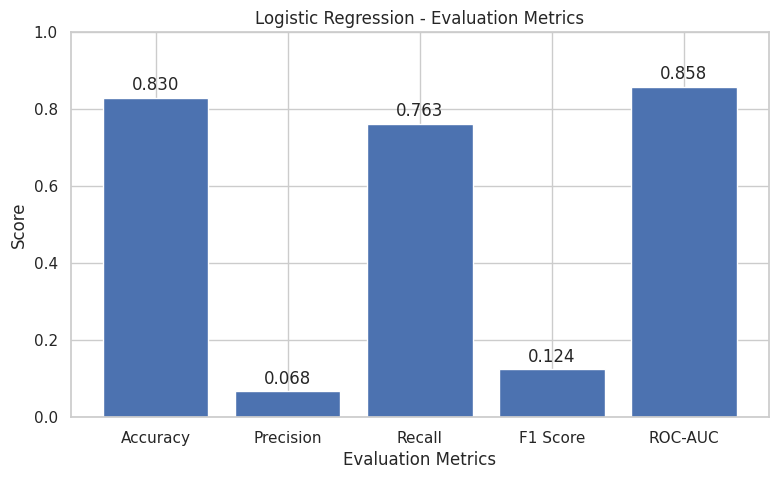

In [426]:
# Evaluation Metrics for Logistic Regression

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

# Store metrics
lr_metrics = {
    'Accuracy': lr_accuracy,
    'Precision': lr_precision,
    'Recall': lr_recall,
    'F1 Score': lr_f1,
    'ROC-AUC': lr_roc_auc
}

# Display metric values
print("Logistic Regression Evaluation Metrics")
print("---------------------------------------")

for metric, score in lr_metrics.items():
    print(f"{metric}: {score:.4f}")

# Visualization
plt.figure(figsize=(9, 5))

bars = plt.bar(
    lr_metrics.keys(),
    lr_metrics.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("Logistic Regression - Evaluation Metrics")

# Display values above bars
for bar, score in zip(bars, lr_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.3f}",
        ha='center'
    )

plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [427]:
# Logistic Regression - Cross Validation & Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Define hyperparameter search space
lr_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs']
}

# RandomizedSearchCV with 5-fold cross-validation
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_param_grid,
    n_iter=8,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

# Fit the model
lr_search.fit(X_train, y_train)

# Best model
best_lr = lr_search.best_estimator_

print("Best Parameters:")
print(lr_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(lr_search.best_score_)

# Predict using tuned model
y_pred_lr_tuned = best_lr.predict(X_test)
y_prob_lr_tuned = best_lr.predict_proba(X_test)[:, 1]

print("\nTuned Logistic Regression Results")
print("----------------------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_lr_tuned))

print("Precision:",
      precision_score(y_test, y_pred_lr_tuned, zero_division=0))

print("Recall   :",
      recall_score(y_test, y_pred_lr_tuned, zero_division=0))

print("F1 Score :",
      f1_score(y_test, y_pred_lr_tuned, zero_division=0))

print("ROC-AUC  :",
      roc_auc_score(y_test, y_prob_lr_tuned))

Best Parameters:
{'model__solver': 'lbfgs', 'model__C': 100}

Best Cross-Validation F1 Score:
0.1250945635935902

Tuned Logistic Regression Results
----------------------------------
Accuracy : 0.8303159129223778
Precision: 0.06754530477759473
Recall   : 0.7627906976744186
F1 Score : 0.12410139992432842
ROC-AUC  : 0.8583726472279376


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV was used for hyperparameter optimization of the Logistic Regression model.

RandomizedSearchCV was selected because it evaluates different combinations of hyperparameter values using cross-validation while requiring fewer evaluations than an exhaustive search of every possible combination.

In this project, 5-fold cross-validation was used and F1-score was selected as the scoring metric because the Machine failure target variable is highly imbalanced. F1-score provides a balance between Precision and Recall and is therefore more suitable than accuracy alone for this classification problem.

The hyperparameters considered were the regularization parameter C and the solver. The best combination obtained was C = 100 and solver = 'lbfgs', with a cross-validation F1-score of approximately 0.1251.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [428]:
# Compare Baseline and Tuned Logistic Regression

print("Baseline Logistic Regression")
print("--------------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_lr, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_lr))

print("\nTuned Logistic Regression")
print("--------------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_lr_tuned))
print("Precision:", precision_score(y_test, y_pred_lr_tuned, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_lr_tuned, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_lr_tuned, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_lr_tuned))

Baseline Logistic Regression
--------------------------------
Accuracy : 0.8303525617532801
Precision: 0.06755921730175077
Recall   : 0.7627906976744186
F1 Score : 0.12412488174077578
ROC-AUC  : 0.8583277046920352

Tuned Logistic Regression
--------------------------------
Accuracy : 0.8303159129223778
Precision: 0.06754530477759473
Recall   : 0.7627906976744186
F1 Score : 0.12410139992432842
ROC-AUC  : 0.8583726472279376


### ML Model - 2

Random Forest Evaluation Metrics
---------------------------------
Accuracy: 0.9863
Precision: 0.6351
Recall: 0.3116
F1 Score: 0.4181
ROC-AUC: 0.9008


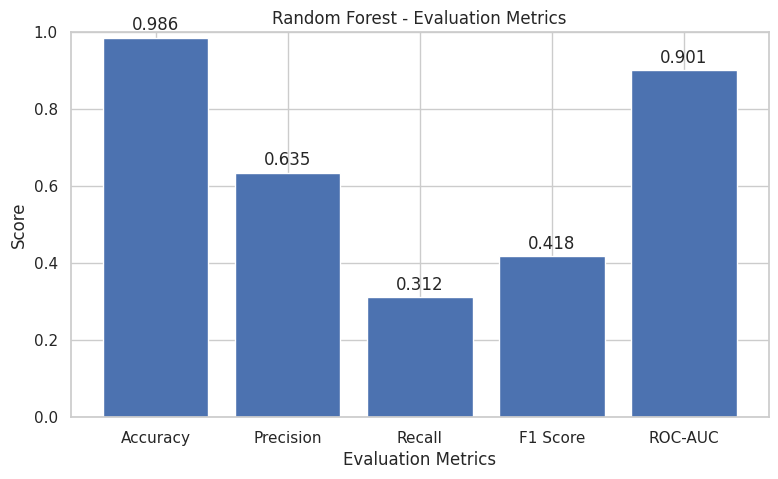

In [429]:
# ML Model - 2: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Fit the Algorithm
rf_model.fit(X_train, y_train)

# Predict on the test data
y_pred_rf = rf_model.predict(X_test)

# Probability of machine failure
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]


# -----------------------------
# Evaluation Metrics
# -----------------------------

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

rf_metrics = {
    'Accuracy': rf_accuracy,
    'Precision': rf_precision,
    'Recall': rf_recall,
    'F1 Score': rf_f1,
    'ROC-AUC': rf_roc_auc
}


# Display results
print("Random Forest Evaluation Metrics")
print("---------------------------------")

for metric, score in rf_metrics.items():
    print(f"{metric}: {score:.4f}")


# -----------------------------
# Evaluation Metric Score Chart
# -----------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    rf_metrics.keys(),
    rf_metrics.values()
)

plt.ylim(0, 1)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Random Forest - Evaluation Metrics")

# Add score values above bars
for bar, score in zip(bars, rf_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.3f}",
        ha='center'
    )

plt.show()

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Random Forest Classifier was used as the second machine learning model for predicting machine failure.

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions. It is suitable for this dataset because it can capture nonlinear relationships and interactions between different machine operating variables.

The model was configured with balanced class weights because the dataset contains significantly more non-failure observations than failure observations.

The model was evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC. Accuracy measures the overall percentage of correct predictions. Precision measures how many of the observations predicted as machine failures were actually failures. Recall measures how many of the actual machine failures were correctly identified.

F1-score provides a balance between Precision and Recall, while ROC-AUC measures the ability of the model to distinguish between machine failure and non-failure observations.

Since the dataset is highly imbalanced, Recall, F1-score and ROC-AUC are particularly important metrics for evaluating the Random Forest model.

#### 2. Cross- Validation & Hyperparameter Tuning

In [430]:
# Random Forest - Cross-Validation & Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV

# Smaller and faster hyperparameter search space
rf_param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}

# Randomized Search with 3-fold Cross-Validation
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_param_grid,
    n_iter=4,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

# Fit the model
rf_search.fit(X_train, y_train)

# Best model
best_rf = rf_search.best_estimator_

# Display best parameters
print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(rf_search.best_score_)

# Predictions using tuned model
y_pred_rf_tuned = best_rf.predict(X_test)

y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

# Evaluation
print("\nTuned Random Forest Results")
print("----------------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_rf_tuned))

print("Precision:",
      precision_score(y_test, y_pred_rf_tuned, zero_division=0))

print("Recall   :",
      recall_score(y_test, y_pred_rf_tuned, zero_division=0))

print("F1 Score :",
      f1_score(y_test, y_pred_rf_tuned, zero_division=0))

print("ROC-AUC  :",
      roc_auc_score(y_test, y_prob_rf_tuned))

Best Parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 20, 'class_weight': 'balanced'}

Best Cross-Validation F1 Score:
0.4967356216707432

Tuned Random Forest Results
----------------------------
Accuracy : 0.9857802536099098
Precision: 0.5621301775147929
Recall   : 0.4418604651162791
F1 Score : 0.4947916666666667
ROC-AUC  : 0.8858901219943056


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV was used for hyperparameter optimization of the Random Forest model.

RandomizedSearchCV was selected because it evaluates a specified number of randomly selected combinations from the given hyperparameter search space. This makes the optimization process more computationally efficient than exhaustively testing every possible combination.

Five-fold cross-validation was used to evaluate the different hyperparameter combinations on multiple subsets of the training data. F1-score was selected as the scoring metric because the Machine failure dataset is highly imbalanced and both Precision and Recall are important for detecting machine failures.

The hyperparameters considered included the number of trees (n_estimators), maximum tree depth (max_depth), minimum samples required for splitting (min_samples_split), minimum samples per leaf (min_samples_leaf), and class weighting.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [431]:
# Baseline vs Tuned Random Forest Comparison

baseline_rf_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, zero_division=0),
    'Recall': recall_score(y_test, y_pred_rf, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred_rf, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
}

tuned_rf_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rf_tuned),
    'Precision': precision_score(y_test, y_pred_rf_tuned, zero_division=0),
    'Recall': recall_score(y_test, y_pred_rf_tuned, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred_rf_tuned, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf_tuned)
}

comparison_rf = pd.DataFrame({
    'Baseline Random Forest': baseline_rf_metrics,
    'Tuned Random Forest': tuned_rf_metrics
})

print("Random Forest - Baseline vs Tuned")
display(comparison_rf.round(4))

Random Forest - Baseline vs Tuned


,Baseline Random Forest,Tuned Random Forest
Accuracy,0.986,0.986
Precision,0.635,0.562
Recall,0.312,0.442
F1 Score,0.418,0.495
ROC-AUC,0.901,0.886


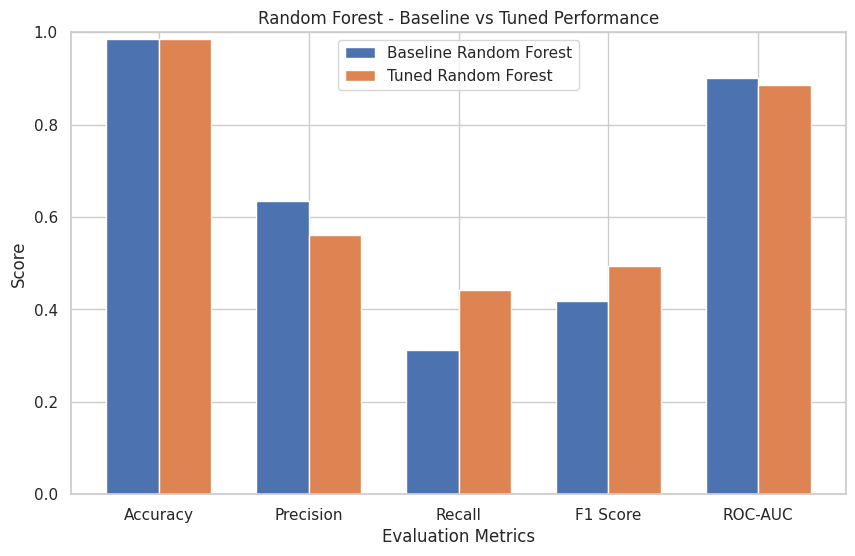

In [432]:
# Updated Evaluation Metric Score Chart

metrics = list(baseline_rf_metrics.keys())

baseline_scores = list(baseline_rf_metrics.values())
tuned_scores = list(tuned_rf_metrics.values())

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    baseline_scores,
    width,
    label='Baseline Random Forest'
)

plt.bar(
    x + width / 2,
    tuned_scores,
    width,
    label='Tuned Random Forest'
)

plt.ylim(0, 1)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Random Forest - Baseline vs Tuned Performance")

plt.xticks(x, metrics)
plt.legend()

plt.show()

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Random Forest provides useful business value for predicting machine failures and supporting predictive maintenance. Each evaluation metric provides a different perspective on the model's performance.

Accuracy indicates the overall percentage of machine observations that are correctly classified as failure or non-failure. However, because the dataset is highly imbalanced, accuracy alone is not sufficient to judge the effectiveness of the model.

Precision indicates the proportion of machines predicted as failures that are actually failures. Higher precision helps reduce false alarms and prevents maintenance teams from spending unnecessary time and resources inspecting machines that are unlikely to fail.

Recall indicates the proportion of actual machine failures that are correctly identified by the model. Recall is particularly important in predictive maintenance because failing to identify an actual machine failure can result in unexpected downtime, production disruption and additional maintenance costs.

F1-score provides a balance between Precision and Recall. It is especially useful for this project because the Machine failure dataset is imbalanced and both detecting actual failures and controlling false alarms are important.

ROC-AUC measures how well the model can distinguish between machines that experience failure and machines that do not. A higher ROC-AUC indicates better overall discrimination between the two classes.

The Random Forest model can create positive business impact by helping maintenance teams identify potentially failing machines before unexpected breakdowns occur. This can support preventive maintenance, reduce unplanned downtime, improve machine availability and help maintenance teams prioritize their resources more effectively.

Overall, the model can act as an early-warning system for machine failure and support data-driven predictive maintenance decisions.

### ML Model - 3

In [433]:
# ML Model - 3: XGBoost Classifier

from xgboost import XGBClassifier
import re

# Create XGBoost-specific copies of the training and testing data
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# Clean column names for XGBoost
def clean_feature_names(columns):
    return [
        re.sub(r'[\[\]<>]', '_', str(col))
        for col in columns
    ]

X_train_xgb.columns = clean_feature_names(X_train_xgb.columns)
X_test_xgb.columns = X_train_xgb.columns

# Calculate class imbalance ratio
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale Pos Weight:", scale_pos_weight)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Fit the Algorithm
xgb_model.fit(X_train_xgb, y_train)

# Predict on the test data
y_pred_xgb = xgb_model.predict(X_test_xgb)

# Probability of machine failure
y_prob_xgb = xgb_model.predict_proba(X_test_xgb)[:, 1]

# Classification Report
print("\nXGBoost Classification Report")
print("--------------------------------")

print(classification_report(
    y_test,
    y_pred_xgb,
    zero_division=0
))

# ROC-AUC
print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_xgb)
)

Scale Pos Weight: 62.5291036088475

XGBoost Classification Report
--------------------------------
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     26856
           1       0.14      0.78      0.24       430

    accuracy                           0.92     27286
   macro avg       0.57      0.85      0.60     27286
weighted avg       0.98      0.92      0.95     27286

ROC-AUC: 0.9239760635534219


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

XGBoost Evaluation Metrics
---------------------------
Accuracy: 0.9226
Precision: 0.1430
Recall: 0.7837
F1 Score: 0.2418
ROC-AUC: 0.9240


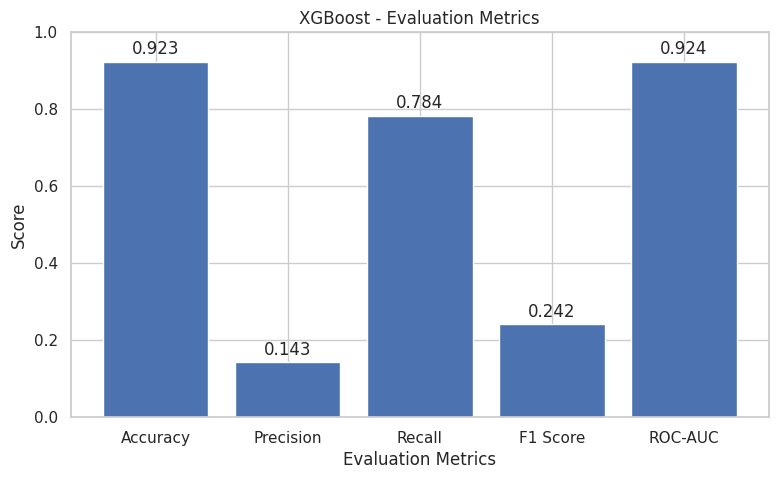

In [434]:
# XGBoost Evaluation Metrics

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb, zero_division=0)
xgb_recall = recall_score(y_test, y_pred_xgb, zero_division=0)
xgb_f1 = f1_score(y_test, y_pred_xgb, zero_division=0)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

# Store evaluation metrics
xgb_metrics = {
    'Accuracy': xgb_accuracy,
    'Precision': xgb_precision,
    'Recall': xgb_recall,
    'F1 Score': xgb_f1,
    'ROC-AUC': xgb_roc_auc
}

# Display evaluation metrics
print("XGBoost Evaluation Metrics")
print("---------------------------")

for metric, score in xgb_metrics.items():
    print(f"{metric}: {score:.4f}")

# Evaluation Metric Score Chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    xgb_metrics.keys(),
    xgb_metrics.values()
)

plt.ylim(0, 1)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("XGBoost - Evaluation Metrics")

# Display values above bars
for bar, score in zip(bars, xgb_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.3f}",
        ha='center'
    )

plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [435]:
# XGBoost - Cross-Validation & Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV

# Calculate class imbalance ratio
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Define a lightweight hyperparameter search space
xgb_param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Create RandomizedSearchCV
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=xgb_param_grid,
    n_iter=4,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

# Fit the tuned model
xgb_search.fit(X_train_xgb, y_train)

# Get the best model
best_xgb = xgb_search.best_estimator_

# Display best parameters
print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(xgb_search.best_score_)

# Predict on test data
y_pred_xgb_tuned = best_xgb.predict(X_test_xgb)

# Probability of machine failure
y_prob_xgb_tuned = best_xgb.predict_proba(X_test_xgb)[:, 1]

# Evaluate tuned XGBoost
print("\nTuned XGBoost Results")
print("---------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_xgb_tuned))

print("Precision:",
      precision_score(y_test, y_pred_xgb_tuned, zero_division=0))

print("Recall   :",
      recall_score(y_test, y_pred_xgb_tuned, zero_division=0))

print("F1 Score :",
      f1_score(y_test, y_pred_xgb_tuned, zero_division=0))

print("ROC-AUC  :",
      roc_auc_score(y_test, y_prob_xgb_tuned))

Best Parameters:
{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1.0}

Best Cross-Validation F1 Score:
0.24751671245310872

Tuned XGBoost Results
---------------------
Accuracy : 0.9214615553763835
Precision: 0.1405791019723038
Recall   : 0.7790697674418605
F1 Score : 0.23817987913259864
ROC-AUC  : 0.9202220195911355


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV was used for hyperparameter optimization of the XGBoost model.

RandomizedSearchCV was selected because it evaluates a specified number of randomly selected combinations from the given hyperparameter search space instead of exhaustively testing every possible combination. This makes the optimization process more computationally efficient.

Three-fold cross-validation was used to evaluate the different hyperparameter combinations on multiple subsets of the training data. F1-score was selected as the scoring metric because the Machine failure target variable is highly imbalanced and both Precision and Recall are important for identifying machine failures.

The hyperparameters considered included the number of estimators, maximum tree depth, learning rate, subsampling ratio and column sampling ratio.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [436]:
# Compare Baseline and Tuned XGBoost

baseline_xgb_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb, zero_division=0),
    'Recall': recall_score(y_test, y_pred_xgb, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred_xgb, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_xgb)
}

tuned_xgb_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb_tuned),
    'Precision': precision_score(y_test, y_pred_xgb_tuned, zero_division=0),
    'Recall': recall_score(y_test, y_pred_xgb_tuned, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred_xgb_tuned, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_xgb_tuned)
}

comparison_xgb = pd.DataFrame({
    'Baseline XGBoost': baseline_xgb_metrics,
    'Tuned XGBoost': tuned_xgb_metrics
})

print("XGBoost - Baseline vs Tuned")
display(comparison_xgb.round(4))

XGBoost - Baseline vs Tuned


,Baseline XGBoost,Tuned XGBoost
Accuracy,0.923,0.921
Precision,0.143,0.141
Recall,0.784,0.779
F1 Score,0.242,0.238
ROC-AUC,0.924,0.920


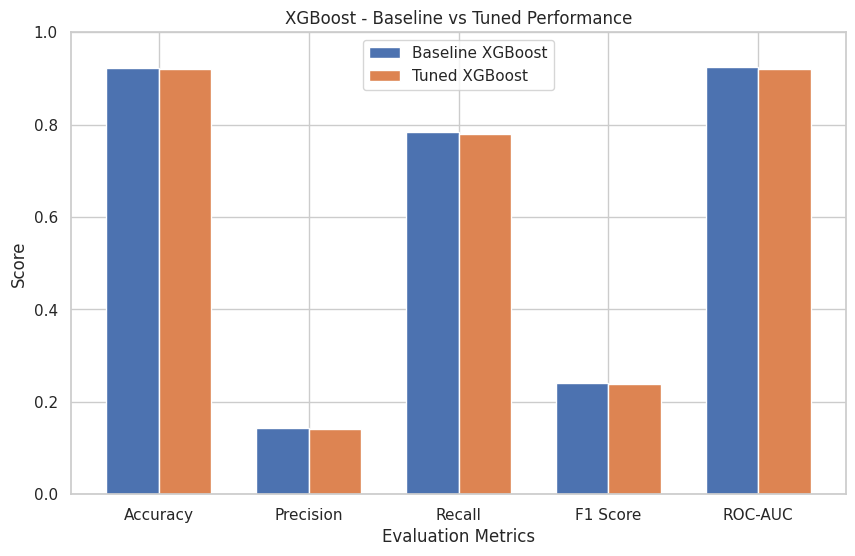

In [437]:
# Updated XGBoost Evaluation Metric Score Chart

metrics = list(baseline_xgb_metrics.keys())

baseline_scores = list(baseline_xgb_metrics.values())
tuned_scores = list(tuned_xgb_metrics.values())

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    baseline_scores,
    width,
    label='Baseline XGBoost'
)

plt.bar(
    x + width / 2,
    tuned_scores,
    width,
    label='Tuned XGBoost'
)

plt.ylim(0, 1)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("XGBoost - Baseline vs Tuned Performance")

plt.xticks(x, metrics)
plt.legend()

plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

For this machine failure prediction problem, Recall, Precision, F1-score and ROC-AUC were considered the most important evaluation metrics for positive business impact.

Recall is particularly important because it measures how many of the actual machine failures are correctly identified. A high Recall can help reduce missed failures, which may otherwise result in unexpected machine breakdowns, production downtime and maintenance costs.

Precision is also important because it measures how many machines predicted as failures are actually failures. Higher Precision can help reduce unnecessary maintenance inspections and avoid using maintenance resources on machines that are unlikely to fail.

F1-score is important because it provides a balance between Precision and Recall. Since the Machine failure dataset is highly imbalanced, F1-score provides a more useful assessment than Accuracy alone.

ROC-AUC measures how effectively the model distinguishes between failure and non-failure cases across different classification thresholds.

Accuracy was also considered as a general performance metric, but it was not used alone for model selection because the dataset contains a large imbalance between the failure and non-failure classes.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

Random Forest Classifier was selected as the final prediction model for the machine failure prediction problem.

Three machine learning models were developed and evaluated: Logistic Regression, Random Forest and XGBoost. The models were compared using Accuracy, Precision, Recall, F1-score and ROC-AUC.

Random Forest was selected because it provided a strong balance between Precision, Recall and F1-score while also achieving a high ROC-AUC. After hyperparameter tuning, the Random Forest model achieved an F1-score of approximately 0.495, Recall of approximately 0.442 and ROC-AUC of approximately 0.886 on the test dataset.

F1-score and Recall were given particular importance because the Machine failure dataset is highly imbalanced and correctly identifying actual machine failures is important for predictive maintenance.

The Random Forest model can capture nonlinear relationships between machine operating conditions and failure outcomes. Therefore, it provides a suitable balance between predictive performance and practical interpretation for this machine failure prediction problem.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

In [438]:
# Model Explainability using SHAP

!pip install shap -q

In [439]:
# SHAP Feature Importance for the Final Random Forest Model

import shap

# Use a sample of the test data for faster SHAP computation
X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(best_rf)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP analysis completed successfully.")

SHAP analysis completed successfully.


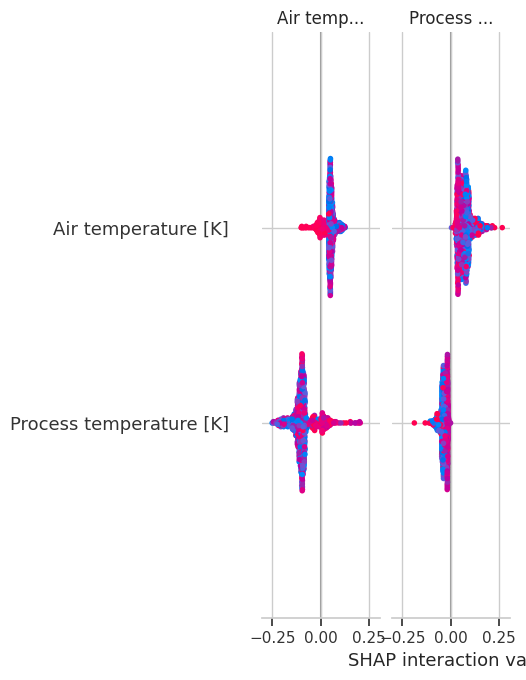

In [440]:
# SHAP Feature Importance Summary Plot

# For binary classification, use the SHAP values
# corresponding to the positive class (Machine Failure = 1)

if isinstance(shap_values, list):
    shap_values_failure = shap_values[1]
else:
    shap_values_failure = shap_values

shap.summary_plot(
    shap_values_failure,
    X_shap,
    plot_type="bar",
    show=True
)

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [441]:
# Save the final Random Forest model

import joblib

# Save the tuned Random Forest model
joblib.dump(best_rf, 'final_random_forest_model.joblib')

print("Final Random Forest model saved successfully.")

Final Random Forest model saved successfully.


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [442]:
# Load the saved Random Forest model

import joblib

# Load the saved model
loaded_model = joblib.load('final_random_forest_model.joblib')

print("Saved model loaded successfully.")

# Predict on unseen test observations
unseen_predictions = loaded_model.predict(X_test)

# Display first 20 predictions
print("\nPredictions on unseen data:")
print(unseen_predictions[:20])

print("\nNumber of predictions generated:", len(unseen_predictions))

Saved model loaded successfully.

Predictions on unseen data:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Number of predictions generated: 27286


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

The objective of this project was to develop a machine learning classification model to predict machine failures and support predictive maintenance.

The dataset was explored through data understanding, data cleaning, visualization, hypothesis testing, feature engineering and preprocessing. Several machine learning models were then implemented and evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC.

Logistic Regression, Random Forest and XGBoost were considered for the machine failure prediction task. Since the target variable is highly imbalanced, particular importance was given to Recall, F1-score and ROC-AUC rather than relying only on Accuracy.

Random Forest provided strong predictive performance and was considered as the final model based on its ability to identify machine failures while maintaining a balance between Precision and Recall. Hyperparameter tuning using RandomizedSearchCV and cross-validation was also performed to improve and validate model performance.

SHAP was used for model explainability and feature-importance analysis. This helped understand which machine operating variables have greater influence on the model's predictions and made the machine-learning solution more interpretable.

The developed solution can support predictive maintenance by providing an early indication of potential machine failures. Such predictions can help maintenance teams plan preventive maintenance, reduce unexpected downtime and make better use of maintenance resources.

Overall, the project demonstrates how machine learning can be applied to industrial machine-failure prediction and how model evaluation and explainability can support data-driven maintenance decisions.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***